In [ ]:
import cv2
import numpy as np
import pandas as pd
import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
from PIL import Image
from tqdm import tqdm
from transformers import CLIPModel, CLIPProcessor
from sklearn.decomposition import PCA
import umap
from sklearn.manifold import TSNE

c:\Users\angelika.vizintin\AppData\Local\anaconda3\envs\msclip\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1110 23:21:16.644000 46132 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [2]:
CSV = "combined_segmentation_quality_v2.csv"
MODEL_PATH = "SeriYann/MicroscopyCLIP"     

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CLIPModel.from_pretrained(MODEL_PATH).to(device).eval()
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

df = pd.read_csv(CSV)      
df.head(2)   

c:\Users\angelika.vizintin\AppData\Local\anaconda3\envs\msclip\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\angelika.vizintin\.cache\huggingface\hub\models--SeriYann--MicroscopyCLIP. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\angelika.vizintin\AppData\Local\anaconda3\envs\msclip\Lib\sit

,image_id,dataset,model,n_true,n_predicted,count_error,TP,FP,FN,precision,...,intensity_p99,contrast,laplacian_variance,noise_estimate,n_cells,cell_density,foreground_fraction,mean_cell_area,median_cell_area,cell_area_cv
0,official_dataset/train/164_img.png,official_dataset/train,cpsam_v2,23,23,0,23,0,0,1.000000,...,8822.707031,8822.707031,0.000413,0.005038,23,117.596531,0.096623,821.652174,797.0,0.406147
1,official_dataset/train/174_img.png,official_dataset/train,cpsam_v2,28,27,-1,25,2,3,0.925926,...,21321.542969,21138.451767,0.000495,0.006189,28,106.811523,0.149349,1398.250000,1412.5,0.499343


In [3]:
def to_display(img):
    """Scale each channel to 0-1 (the 16-bit fix from before)."""
    img = img.astype(float)
    if img.ndim == 2:
        img = np.stack([img] * 3, axis=-1)
    out = np.zeros((*img.shape[:2], 3))
    for c in range(min(3, img.shape[-1])):
        lo, hi = np.percentile(img[..., c], (1, 99))
        if hi > lo:
            out[..., c] = np.clip((img[..., c] - lo) / (hi - lo), 0, 1)
    return out

def load_pil(path):
    image = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if image is None:
        raise FileNotFoundError(path)
    gray = to_display(image).max(axis=-1)                          # strongest channel -> grayscale
    gray = cv2.resize((gray * 255).astype("uint8"), (224, 224))
    image_rgb = np.stack([gray, gray, gray], axis=2)
    return Image.fromarray(image_rgb.astype("uint8"))

In [4]:
embeddings, kept = [], []
with torch.no_grad():
    for i, image_id in enumerate(tqdm(df["image_id"])):
        try:
            inputs = processor.image_processor(images=[load_pil(image_id)], return_tensors="pt").to(device)
            vision_outputs = model.vision_model(pixel_values=inputs["pixel_values"])
            embeddings.append(vision_outputs.pooler_output[0].cpu().numpy())
            kept.append(i)
        except Exception as e:
            print("skipped:", image_id, "|", e)

emb = np.array(embeddings)
emb = emb / np.linalg.norm(emb, axis=1, keepdims=True)             # unit length, as usual for CLIP
meta = df.iloc[kept].reset_index(drop=True)

np.save("msclip_embeddings.npy", emb)                               # same row order as meta
meta[["image_id"]].to_csv("msclip_embeddings_image_ids.csv", index=False)

 94%|█████████▍| 936/993 [00:37<00:07,  7.18it/s]

skipped: flow_chamber_dataset/training_dataset/training_source/t:3901-5941 - FOV1 B.czi #1.tif | flow_chamber_dataset/training_dataset/training_source/t:3901-5941 - FOV1 B.czi #1.tif


 95%|█████████▍| 939/993 [00:38<00:08,  6.29it/s]

skipped: flow_chamber_dataset/training_dataset/training_source/t:901-5941 - FOV1 B.czi #1.tif | flow_chamber_dataset/training_dataset/training_source/t:901-5941 - FOV1 B.czi #1.tif
skipped: flow_chamber_dataset/training_dataset/training_source/t:5701-5941 - FOV1 B.czi #1.tif | flow_chamber_dataset/training_dataset/training_source/t:5701-5941 - FOV1 B.czi #1.tif


 95%|█████████▍| 942/993 [00:38<00:06,  8.00it/s]

skipped: flow_chamber_dataset/training_dataset/training_source/t:2401-5941 - FOV1 B.czi #1.tif | flow_chamber_dataset/training_dataset/training_source/t:2401-5941 - FOV1 B.czi #1.tif


... (17 outputs left out)

skipped: flow_chamber_dataset/training_dataset/training_source/t:4801-5941 - FOV1 B.czi #1.tif | flow_chamber_dataset/training_dataset/training_source/t:4801-5941 - FOV1 B.czi #1.tif


100%|█████████▉| 990/993 [00:46<00:00,  4.24it/s]

skipped: flow_chamber_dataset/training_dataset/training_source/t:3001-5941 - FOV1 B.czi #1.tif | flow_chamber_dataset/training_dataset/training_source/t:3001-5941 - FOV1 B.czi #1.tif


100%|██████████| 993/993 [00:46<00:00, 21.24it/s]


In [5]:
# --- Images that were skipped the first time ---
missing = df[~df["image_id"].isin(meta["image_id"])]
print("to reprocess:", len(missing))

new_emb, new_idx = [], []
with torch.no_grad():
    for i, image_id in tqdm(missing["image_id"].items(), total=len(missing)):
        try:
            path = image_id.replace(":", "_")             # renamed file on disk (see rename_map.csv)
            inputs = processor.image_processor(images=[load_pil(path)], return_tensors="pt").to(device)
            vision_outputs = model.vision_model(pixel_values=inputs["pixel_values"])
            new_emb.append(vision_outputs.pooler_output[0].cpu().numpy())
            new_idx.append(i)
        except Exception as e:
            print("skipped:", image_id, "|", e)

# --- Append to the existing results (image_id keeps the original name, so it still matches the metrics CSV) ---
new_emb = np.array(new_emb)
new_emb = new_emb / np.linalg.norm(new_emb, axis=1, keepdims=True)

emb = np.vstack([emb, new_emb])
meta = pd.concat([meta, df.loc[new_idx]], ignore_index=True)

np.save("msclip_embeddings.npy", emb)
meta[["image_id"]].to_csv("msclip_embeddings_image_ids.csv", index=False)
print("total embeddings:", emb.shape)

to reprocess: 20


100%|██████████| 20/20 [00:04<00:00,  4.30it/s]

total embeddings: (993, 768)


In [ ]:
pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(emb)

X_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(emb)
X_umap = umap.UMAP(n_components=2, random_state=0).fit_transform(emb)

spaces = [   # (coordinates, x label, y label)
    (X_pca, f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", f"PC2 ({pca.explained_variance_ratio_[1]:.0%})"),
    (X_tsne, "t-SNE 1", "t-SNE 2"),
    (X_umap, "UMAP 1", "UMAP 2"),
]

def short(name):
    parts = name.split("/")
    return "official/" + parts[1] if parts[0] == "official_dataset" else parts[0]

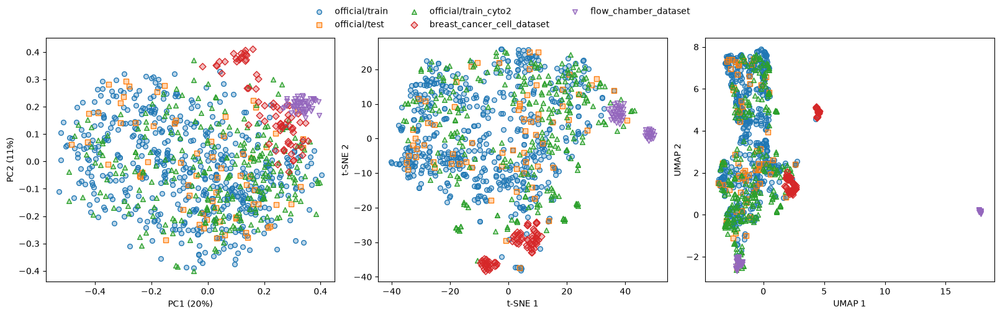

In [21]:
MARKERS = ["o", "s", "^", "D", "v", "P", "X"]      # one per dataset
CMAP = plt.get_cmap("viridis").copy()
CMAP.set_bad("lightgrey")                            # colour for missing (NaN) metric values


labels = meta["dataset"].map(short)
datasets = list(labels.unique())
marker_of = {d: MARKERS[i] for i, d in enumerate(datasets)}
color_of = {d: plt.cm.tab10(i) for i, d in enumerate(datasets)}
masks = {d: (labels == d).to_numpy() for d in datasets}

fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for ax, (X, xl, yl) in zip(axes, spaces):
    for d in datasets:
        m, c = masks[d], color_of[d]
        ax.scatter(X[m, 0], X[m, 1], s=30, marker=marker_of[d], facecolor=to_rgba(c, 0.3),
                   edgecolor=c, linewidth=1, label=f"{d}")
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="outside upper center", ncol=3, frameon=False)       # legend above the plots
plt.show()

Images from all the 3 cellpose datasets are evenly distributed in the downprojected space while images from the breast cancer and flow chamber dataset form their own clusters, especially a subset of the flow chamber dataset seems to be distinc from the other images which could explain the worse model performance on this dataset.

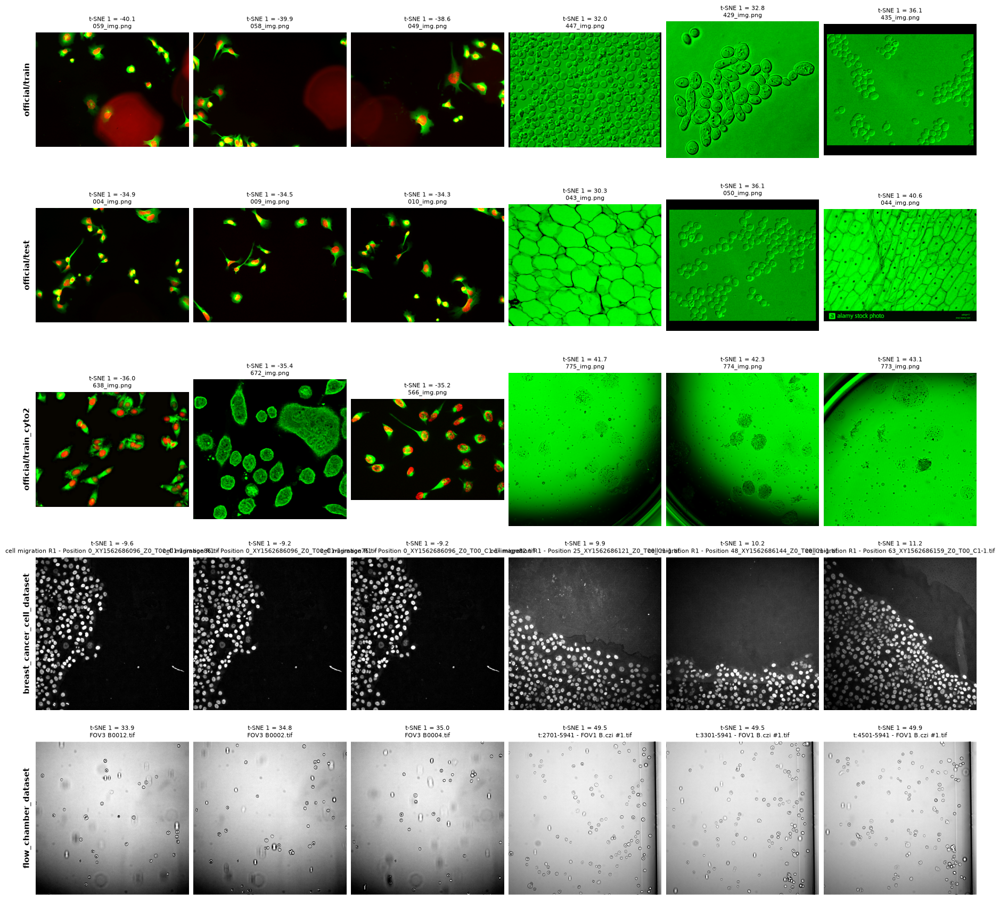

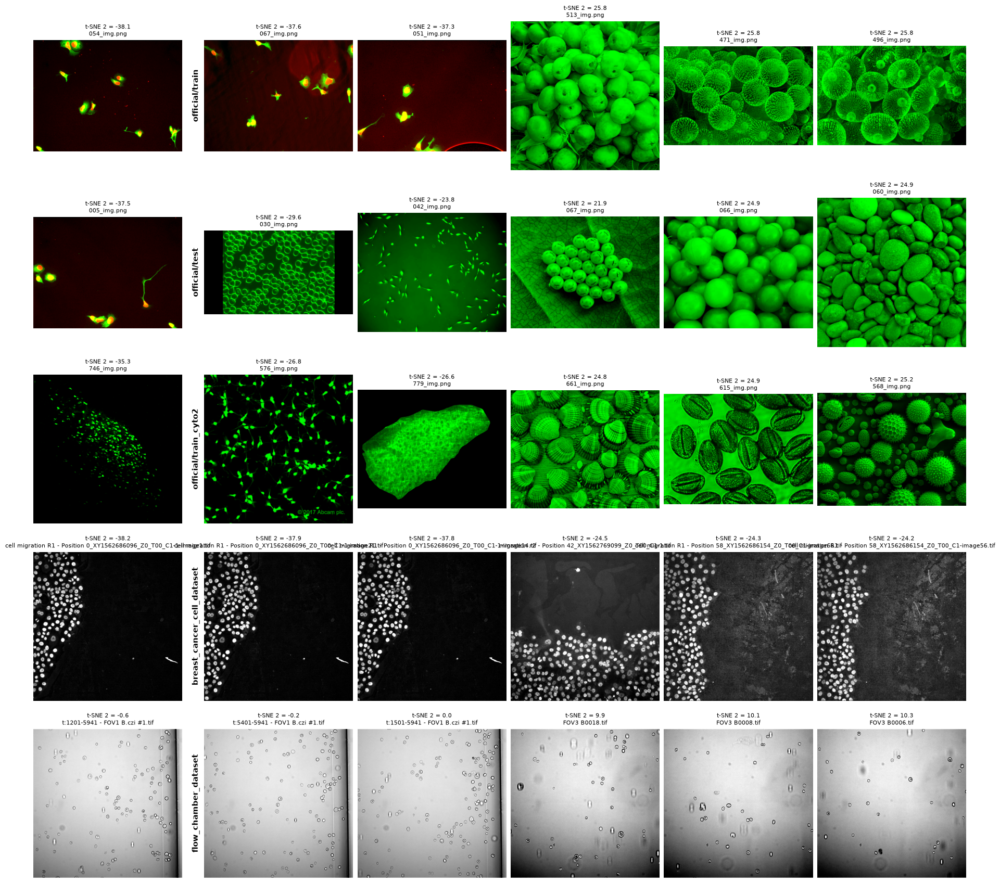

In [28]:
# To get a filling how images from different t-SNE "clusters" look like, we show the N lowest and N highest t-SNE 1 values for each dataset.

import cv2

N = 3

def load_rgb(image_id):
    img = cv2.imread(image_id.replace(":", "_"), cv2.IMREAD_UNCHANGED)   # renamed files, see rename_map.csv
    if img.ndim == 3 and img.shape[-1] >= 3:
        img = img[..., [2, 1, 0]]                  
    return to_display(img)                    

fig, axes = plt.subplots(len(datasets), 2 * N, figsize=(3 * 2 * N, 3.4 * len(datasets)), constrained_layout=True)

for row, d in enumerate(datasets):
    idx = np.flatnonzero(masks[d])                            
    order = idx[np.argsort(X_tsne[idx, 0])]                    
    selected = list(order[:N]) + list(order[-N:])               

    for col, i in enumerate(selected):
        ax = axes[row, col]
        ax.imshow(load_rgb(meta.loc[i, "image_id"]))
        ax.set_axis_off()
        side = "lowest" if col < N else "highest"
        ax.set_title(f"t-SNE 1 = {X_tsne[i, 0]:.1f}\n{meta.loc[i, 'image_id'].split('/')[-1]}", fontsize=8)

    # dataset name at the left of each row
    axes[row, 0].text(-0.03, 0.5, d, transform=axes[row, 0].transAxes, rotation=90,
                      ha="right", va="center", fontsize=11, fontweight="bold")

plt.show()


fig, axes = plt.subplots(len(datasets), 2 * N, figsize=(3 * 2 * N, 3.4 * len(datasets)), constrained_layout=True)

for row, d in enumerate(datasets):
    idx = np.flatnonzero(masks[d])                            
    order = idx[np.argsort(X_tsne[idx, 1])]                    
    selected = list(order[:N]) + list(order[-N:])               

    for col, i in enumerate(selected):
        ax = axes[row, col]
        ax.imshow(load_rgb(meta.loc[i, "image_id"]))
        ax.set_axis_off()
        side = "lowest" if col < N else "highest"
        ax.set_title(f"t-SNE 2 = {X_tsne[i, 1]:.1f}\n{meta.loc[i, 'image_id'].split('/')[-1]}", fontsize=8)

    # dataset name at the left of each row
    axes[row, 0].text(-0.03, 0.5, d, transform=axes[row, 1].transAxes, rotation=90,
                      ha="right", va="center", fontsize=11, fontweight="bold")

plt.show()

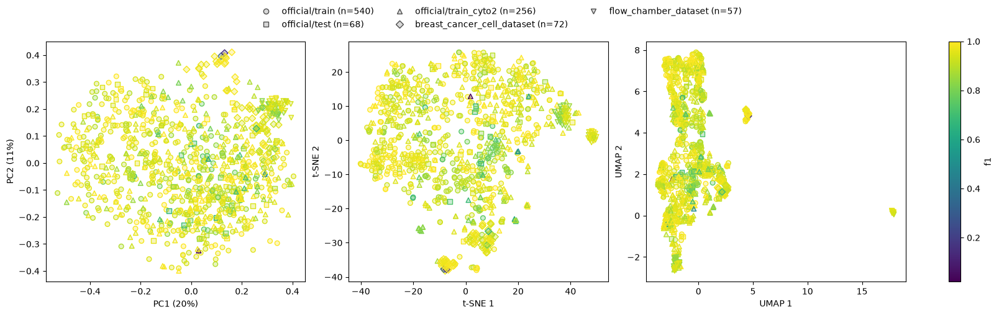

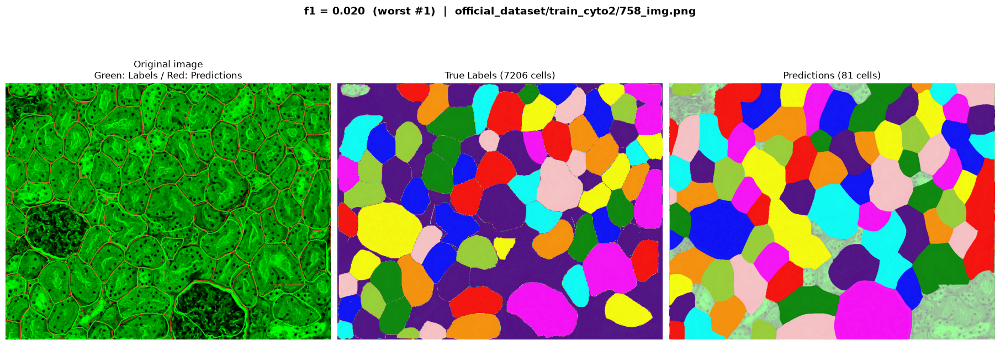

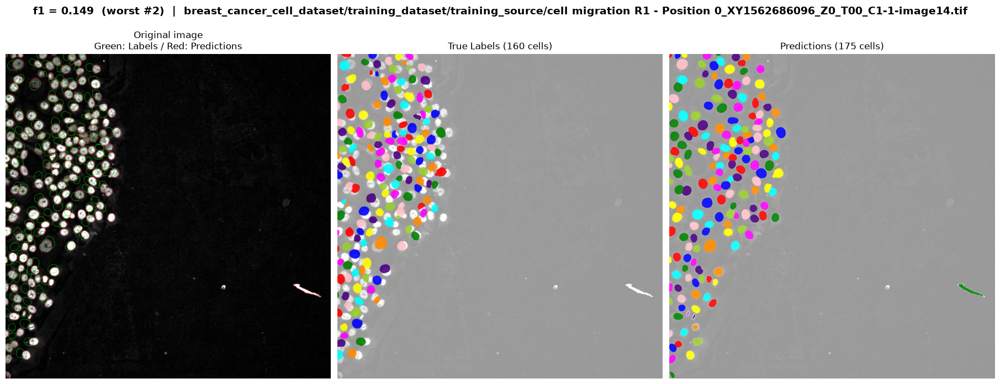

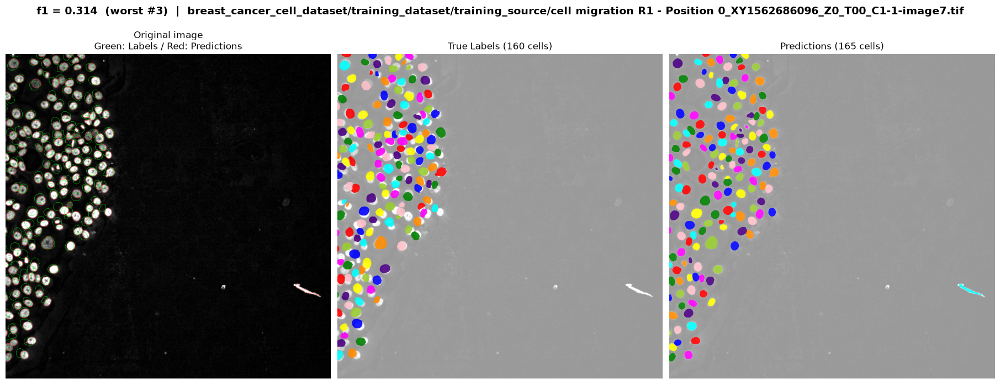

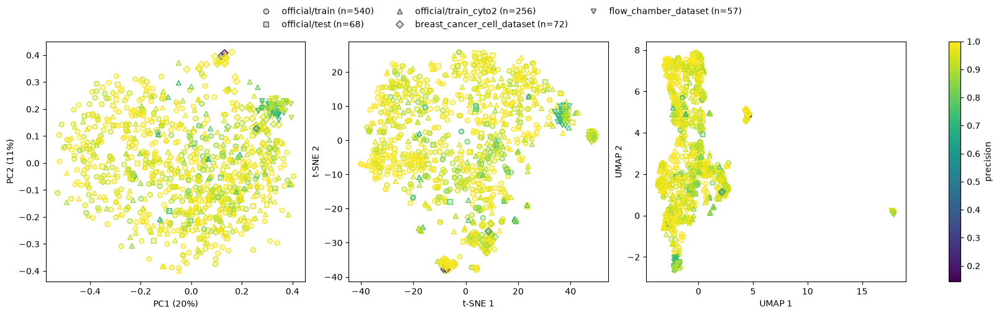

...

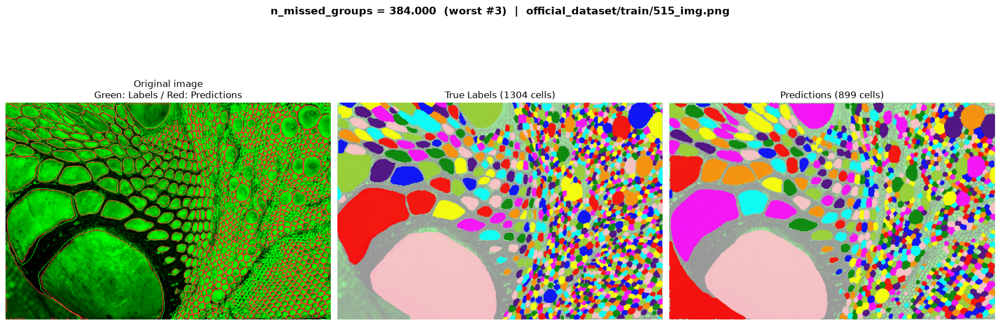

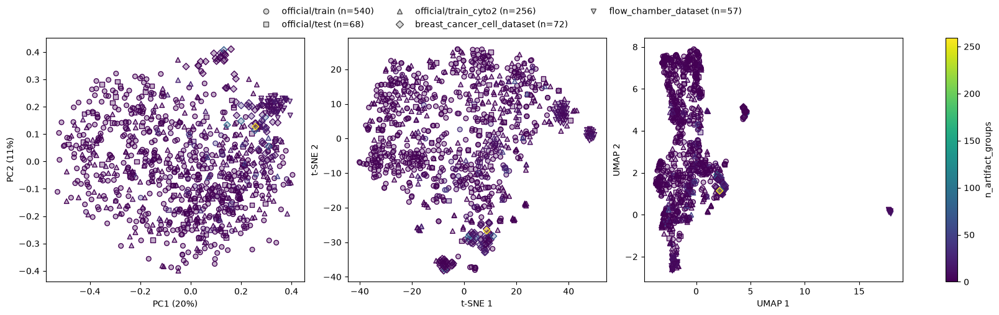

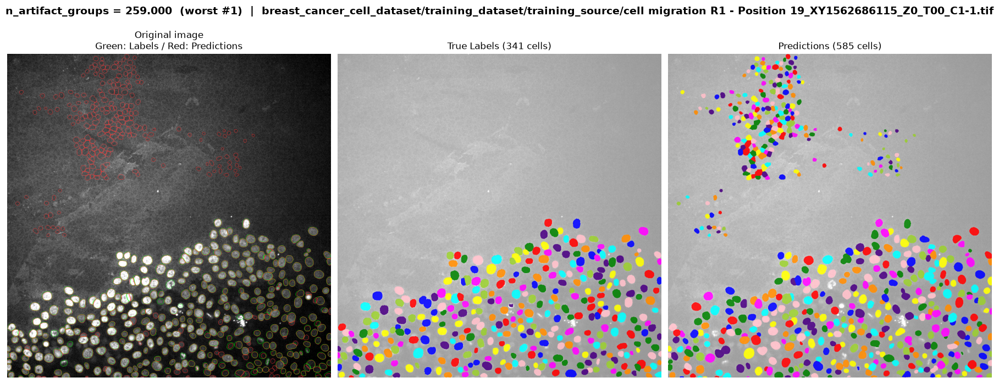

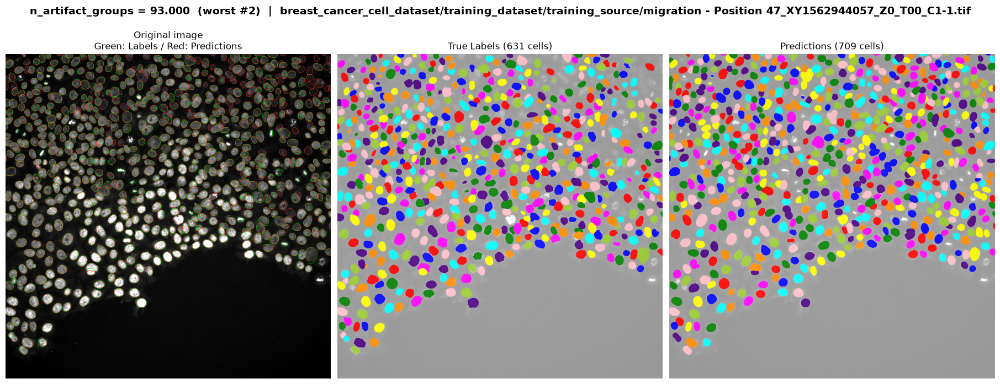

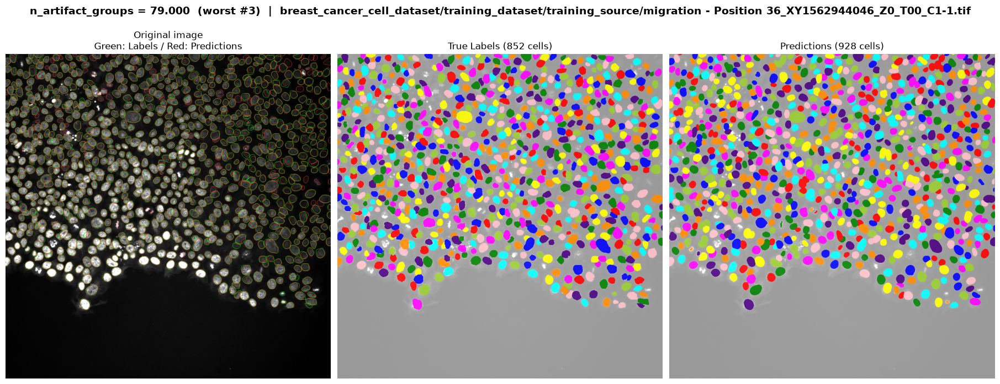

In [30]:
from pathlib import Path
import torch
from cellpose import models, io
from skimage.segmentation import find_boundaries
from skimage.color import label2rgb

N_EXAMPLES = 3
METRICS_LIST = [
    "f1", "precision", "recall", "ap50", "ap75", "ap90", "count_error",
    "mean_iou", "median_iou", "mean_dice", "foreground_iou", "foreground_dice",
    "aji_custom", "aji_official",
    "b_f1_50", "b_f1_75", "b_f1_90",
    "n_split_groups", "n_merged_groups", "n_complex_groups", "n_missed_groups", "n_artifact_groups",
]
# Same rules as in example_images_worst_best_metrics.ipynb
HIGHER_IS_WORSE = ["n_split_groups", "n_merged_groups", "n_complex_groups",
                   "n_missed_groups", "n_artifact_groups"]
ABS_IS_WORSE = ["count_error"]

# --- Cellpose model (named cp_model so it doesn't clash with the CLIP `model`) ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cp_model = models.CellposeModel(pretrained_model="cpsam_v2", device=device)
predictions = {}      # cache: the same image can be among the worst for several metrics

def worst_rows(metric, n):
    d = meta.dropna(subset=[metric])
    if metric in ABS_IS_WORSE:
        d = d.reindex(d[metric].abs().sort_values(ascending=False).index)
    elif metric in HIGHER_IS_WORSE:
        d = d.sort_values(metric, ascending=False)
    else:
        d = d.sort_values(metric)
    return d.head(n)

def show_example(row, metric, rank):
    image_id = row["image_id"]

    # paths (colon in the name -> renamed file, see rename_map.csv)
    image_path = Path(image_id.replace(":", "_"))
    if "_img" in image_path.name:                                      # official_dataset
        mask_path = image_path.parent / image_path.name.replace("img", "masks")
    else:                                                              # breast_cancer / flow_chamber
        mask_path = image_path.parent.parent / "training_target" / image_path.name

    # read and predict
    image = io.imread(image_path)
    true_cells = io.imread(mask_path)
    if image_id not in predictions:
        predictions[image_id], _, _ = cp_model.eval(image)
    predicted_cells = predictions[image_id]

    rgb = to_display(image)
    fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharex=True, sharey=True, constrained_layout=True)
    ax_input, ax_true, ax_pred = axes

    ax_input.imshow(rgb)
    true_edges = np.zeros((*true_cells.shape, 4))
    pred_edges = np.zeros((*predicted_cells.shape, 4))
    true_edges[find_boundaries(true_cells, mode="inner")] = [0, 1, 0, 0.9]
    pred_edges[find_boundaries(predicted_cells, mode="inner")] = [1, 0.2, 0.2, 0.9]
    ax_input.imshow(true_edges)
    ax_input.imshow(pred_edges)
    ax_input.set_title("Original image\nGreen: Labels / Red: Predictions")

    for ax, cells, title in [(ax_true, true_cells, "True Labels"), (ax_pred, predicted_cells, "Predictions")]:
        ax.imshow(rgb, alpha=0.4)
        overlay = np.dstack([label2rgb(cells, bg_label=0), (cells > 0) * 0.9])
        ax.imshow(overlay)
        ax.set_title(f"{title} ({len(np.unique(cells)) - 1} cells)")

    for ax in axes:
        ax.set_axis_off()

    fig.suptitle(f"{metric} = {row[metric]:.3f}  (worst #{rank})  |  {image_id}\n",
                 fontsize=14, fontweight="bold")
    plt.show()


legend_handles = [
    Line2D([], [], marker=marker_of[d], linestyle="", markerfacecolor=(0.5, 0.5, 0.5, 0.3),
           markeredgecolor="0.3", label=f"{d} (n={masks[d].sum()})")
    for d in datasets
]

for metric in METRICS_LIST:
    values = meta[metric].to_numpy(dtype=float)
    norm = Normalize(np.nanmin(values), np.nanmax(values))

    fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
    for ax, (X, xl, yl) in zip(axes, spaces):
        for d in datasets:
            m = masks[d]
            edge = CMAP(norm(values[m]))              # solid border in the metric colour
            face = edge.copy()
            face[:, 3] = 0.3                          # fill with alpha = 0.3
            ax.scatter(X[m, 0], X[m, 1], s=30, marker=marker_of[d], facecolor=face, edgecolor=edge, linewidth=1)
        ax.set_xlabel(xl)
        ax.set_ylabel(yl)

    fig.legend(handles=legend_handles, loc="outside upper center", ncol=3, frameon=False)   # legend above the plots
    fig.colorbar(ScalarMappable(norm=norm, cmap=CMAP), ax=axes, label=metric)                # one shared colourbar
    plt.show()

    # the N worst images for this metric
    for rank, (_, row) in enumerate(worst_rows(metric, N_EXAMPLES).iterrows(), start=1):
        show_example(row, metric, rank)

With the metrics it doesn't seem that images that perform worst according to a certain metrics would cluster together in the donwrojected space, for some metrics images from the same dataset all perform comparably. Also noticed that in some of the "worse" images according to certain metrics (e.g. median IOU, mean DICE) actually the ground truth masks seem to be quite bad.